In [1]:
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp, ttest_ind
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
%load_ext autoreload
%autoreload 2
import os
NCPU = "5"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [15]:
split_thres = (0.6, 0.8)
addon = 'unfiltered'
downlims = [10,4,10]
load_data = True

train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims)
full_graph_train = get_extended_condensed_data(train_scaled)

Loaded successfully


In [42]:
all_models = {}
all_cms = {}
graphic_trains = {}
for i in range(5):
    split_thres = (round(i*0.2, 1), round((i+1)*0.2, 1))
    addon = 'unfiltered'
    starting_from = 0
    downlims = [10,4,10]
    if addon=='downisiset':
        addon = f"{addon}{str(downlims)}{str(starting_from)[2]}"
    elif addon in ["downisitime", "downtime"]:
        addon += str(starting_from)[2]
    load_data = True
    grouping_vars = {"by_animal":True}
    train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims,
                                                             starting_from=starting_from,grouping=grouping_vars,
                                                             save_data_after=False)
    graphic_train = get_extended_condensed_data(train_scaled)
    groupings, group_labels, _, _, _, _ = get_cell_groupings(graphic_train, **grouping_vars)
    def replace_with_label(cell):
        for i,group in enumerate(groupings):
            if cell in group:
                return group_labels[i]
        return ""
    graphic_train['label'] = graphic_train.cell.apply(replace_with_label)
    graphic_train = graphic_train.drop_duplicates(['label'])
    graphic_trains[i] = graphic_train
    models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'], **grouping_vars)
    cms = get_cms_multi(test_scaled, models, get_spiking=True, grouping_vars=grouping_vars)
    all_models[i] = models
    all_cms[i] = cms

Loading Dataset
adding column if necessary
Filtering out lame neurons
Splitting into train/test 500 isi chunks


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [01:03<00:00, 67.94it/s]


Add in some ids
minimizing stuff in the train dataset
Not filtering the dataset/downsampling isis, assuming this is intentional!
Resampling and doing spike metrics
Spike metrics beginning!


  0%|                                                                                                                                         | 0/1790507 [00:00<?, ?it/s]/hlabhome/wg-mjames/.conda/envs/james_home/lib/python3.11/site-packages/elephant/statistics.py:591: UserWarning: No units specified for R, assuming milliseconds (ms)
  warnings.warn('No units specified for R, assuming milliseconds (ms)')
/hlabhome/wg-mjames/.conda/envs/james_home/lib/python3.11/site-packages/elephant/statistics.py:600: UserWarning: No units specified for time_intervals, assuming milliseconds (ms)
  warnings.warn('No units specified for time_intervals,'
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1790507/1790507 [00:31<00:00, 56002.24it/s]


Spike metrics beginning!


...

 88%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎               | 15/17 [00:32<00:04,  2.49s/it]

104118


 94%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏       | 16/17 [00:34<00:02,  2.45s/it]

112634


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:01<00:00, 13.02it/s]


In [4]:
graphic_trains

{0:         index  state region                            cell  animal celltype  \
 0           0      2   ACad        caf69_358_1228_0_12_6_wt   caf69      RSU   
 876    178459      2     V1   caf71_492_0103_0_12_3_app_ps1   caf71       FS   
 1467   256782      2   ACad   caf73_381_0120_4_15_1_app_ps1   caf73      RSU   
 2397   432684      2   ACad  caf74_419_0125_48_60_4_app_ps1   caf74      RSU   
 3087   559298      2   ACad  caf75_389_0125_53_64_6_app_ps1   caf75       FS   
 3825   648524      2   RSPv        caf77_394_0202_0_12_3_wt   caf77       FS   
 4092   706231      2   ACad        caf81_455_0304_0_12_1_wt   caf81       FS   
 5103   887503      2    CA1        caf82_455_0304_0_12_4_wt   caf82      RSU   
 5604  1004261      2     V1       zbr106_101_0223_0_12_2_wt  zbr106      RSU   
 6182  1123887      2     V1   zbr113_91_0513_0_12_1_app_ps1  zbr113      RSU   
 6269  1144141      2     V1   zbr114_73_0426_0_12_2_app_ps1  zbr114      RSU   
 6719  1218927      2   R

In [2]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/neuron_holdouts/gtrains", "rb") as f:
    graphic_trains = pickle.load(f)
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/neuron_holdouts/cmsplits", "rb") as f:
    all_cms = pickle.load(f)
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/neuron_holdouts/logmodels", "rb") as f:
    all_models = pickle.load(f)

In [83]:
summed_conf = all_cms[i]["LogRegGroup_over"]
for group in summed_conf:
    summed_conf[group] = [*summed_conf[group]]
    arrs = []
    for i in range(5):
        arrs.append(all_cms[i]["LogRegGroup_over"][group][0])
    print(np.average(arrs, axis=0))
    summed_conf[group][0] = np.average(arrs, axis=0)

[[0.49177837 0.21195983 0.3074618 ]
 [0.30250008 0.3521186  0.35658132]
 [0.29523578 0.27106493 0.44489929]]
[[0.64280192 0.19286437 0.17233372]
 [0.21518294 0.49785846 0.2949586 ]
 [0.2486478  0.35906833 0.40028386]]
[[0.69567718 0.13426524 0.17805757]
 [0.29725902 0.41120587 0.29953511]
 [0.28993091 0.3743122  0.34375689]]
[[0.38801051 0.33617603 0.28381347]
 [0.25271939 0.49272152 0.26255909]
 [0.32371965 0.31255801 0.37172235]]
[[0.60871519 0.19839614 0.20088867]
 [0.25813152 0.49605265 0.25381583]
 [0.37317234 0.30359264 0.33123502]]
[[0.64723598 0.13947995 0.22128407]
 [0.17244688 0.60513782 0.2304153 ]
 [0.24347853 0.39793545 0.36658602]]
[[0.64812072 0.15774965 0.20212963]
 [0.21547134 0.4224228  0.37010587]
 [0.17312909 0.24794339 0.58692752]]
[[0.67627078 0.15250925 0.17921998]
 [0.24542475 0.36085298 0.40172227]
 [0.21207295 0.31800515 0.47792189]]
[[0.81561031 0.10884239 0.0835473 ]
 [0.2239582  0.33199689 0.45204491]
 [0.10001027 0.25934885 0.64864088]]
[[0.77463504 0.1097

In [108]:
get_mean_cms_visual(summed_conf,full_graph_train, by_geno=False, by_age=False,
                    prev_group_by_anim=True, subplot_kwargs={"figsize":(4.8,4), 'dpi':300}, addon_text=False,
                   alt_se=True, )

SyntaxError: keyword argument repeated: subplot_kwargs (1717600030.py, line 3)

In [94]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/by_animal/cms.pkl", "rb") as f:
            by_animal_cms = pickle.load(f)

In [107]:
comp = {}
bas = {}
for group in by_animal_cms:
    comp[group] = [(by_animal_cms[group][0]), summed_conf[group][0]]
    bas[group] = [accuracy(by_animal_cms[group][0]), accuracy(summed_conf[group][0])]
zipped = [[i[0] for i in bas.values()], [i[1] for i in bas.values()]]
scipy.stats.ttest_rel(zipped[0], zipped[1], alternative='greater')

[[np.float64(0.47069588562436665), np.float64(0.495347970344225), np.float64(0.49294061213450296), np.float64(0.37312371810095973), np.float64(0.4968025194768191), np.float64(0.5563523614078326), np.float64(0.5319129854213072), np.float64(0.5655433950432831), np.float64(0.6914669744100476), np.float64(0.6274819070031572), np.float64(0.6162592019813916), np.float64(0.6564378528049176), np.float64(0.5465569596143416), np.float64(0.601106648663438), np.float64(0.656533931863891), np.float64(0.6467473878550019), np.float64(0.6209621048300303)], [np.float64(0.42959875423851485), np.float64(0.5136480801115314), np.float64(0.48354664757198523), np.float64(0.41748479338561967), np.float64(0.47866762016579073), np.float64(0.5396532748837859), np.float64(0.5524903452472946), np.float64(0.5050152187384678), np.float64(0.5987493622796177), np.float64(0.6258552642268608), np.float64(0.5611301193962921), np.float64(0.5344822888016911), np.float64(0.5545144908359271), np.float64(0.5861071998313311), 

TtestResult(statistic=np.float64(2.837626310689904), pvalue=np.float64(0.005940616856941859), df=np.int64(16))

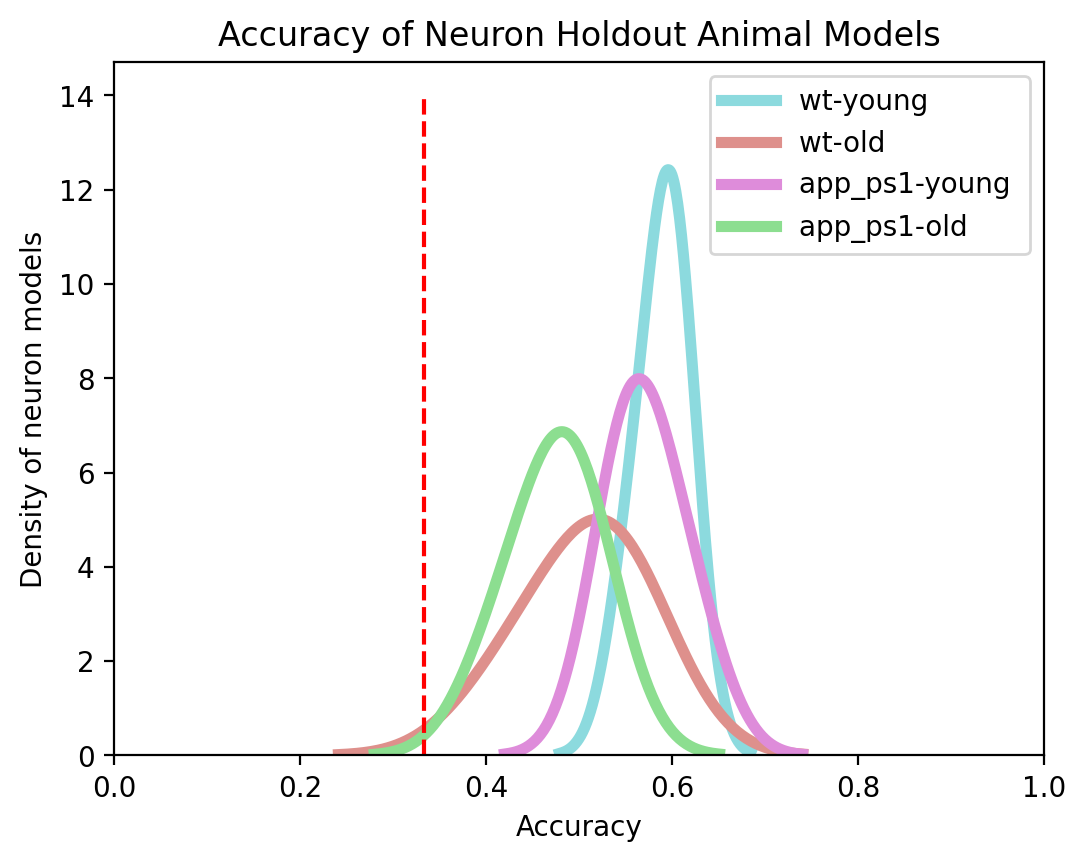

In [93]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(6,4.5))
get_cm_distrib_hist(summed_conf,full_graph_train, "Accuracy of Neuron Holdout Animal Models",
                    by_geno=True, by_age=True, kde=True,
                        prev_group_by_anim=True,linewidth=4, bw_adjust=1.5)

Datapoints per: 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5


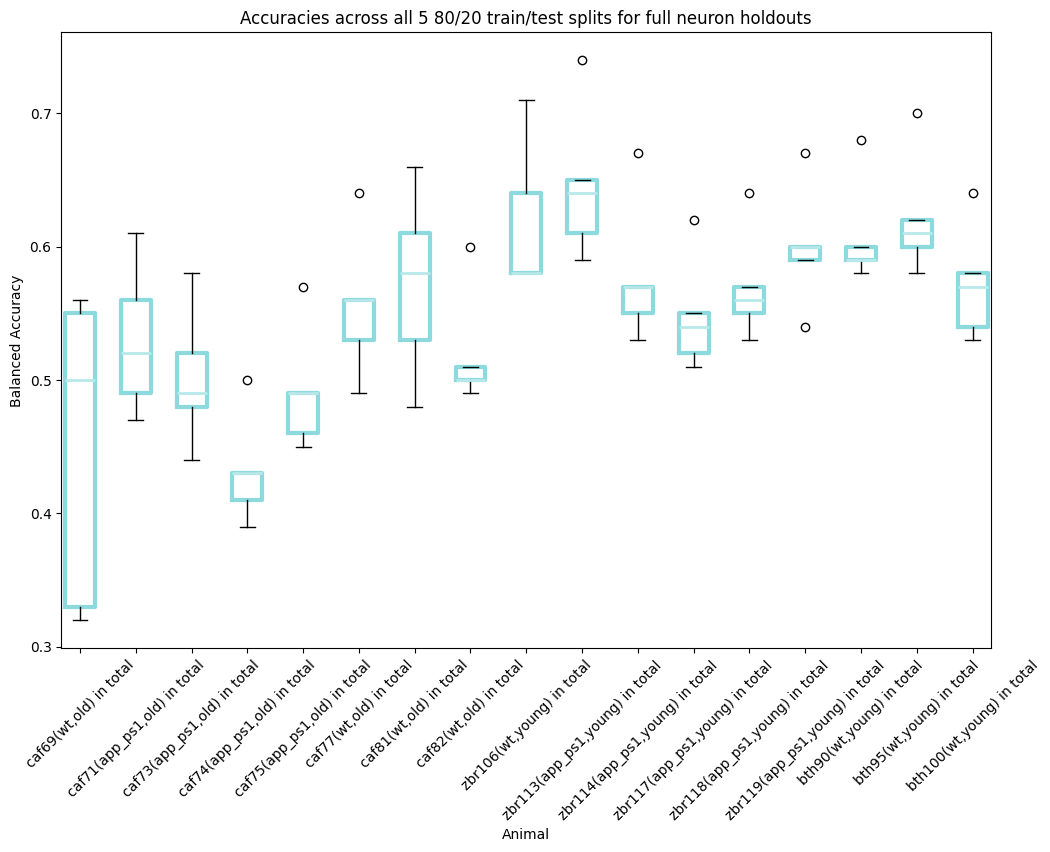

In [74]:
all_splits ={}
for k in all_cms:
    for name, dct in all_cms[k]['LogRegGroup_over'].items():
        if name not in all_splits:
            all_splits[name] = []
        all_splits[name].append(float(round(accuracy(dct[0]), 2)))
        #print(name, accuracy(dct[0]))
#print(all_splits)
box_whisker(all_splits.values(), inner_d2=False, color_by_group=False, labels=all_splits.keys(), rotat=45)
plt.ylabel("Balanced Accuracy")
plt.xlabel("Animal")
plt.title("Accuracies across all 5 80/20 train/test splits for full neuron holdouts")
plt.show()

In [65]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/neuron_holdouts/gtrains", "wb") as f:
    pickle.dump(graphic_trains, f)

In [31]:
grouping_vars = {"by_animal":True}

In [37]:
#models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'], **grouping_vars)
cms = get_cms_multi(test_scaled, models, get_spiking=True, grouping_vars=grouping_vars)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:00<00:00, 22.64it/s]


In [54]:
grouping_vars = {"by_animal":True, "by_ntype":True}

In [55]:
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'], **grouping_vars)
cms = get_cms_multi(test_scaled, models, get_spiking=True)

  0%|                                                                                                                                              | 0/34 [00:00<?, ?it/s]

59825


  3%|███▉                                                                                                                                  | 1/34 [00:00<00:17,  1.91it/s]

110827


  6%|███████▉                                                                                                                              | 2/34 [00:01<00:28,  1.13it/s]

...

 94%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏       | 32/34 [00:24<00:01,  1.33it/s]

39718


 97%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████    | 33/34 [00:25<00:00,  1.39it/s]

63137


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 34/34 [00:00<00:00, 46.93it/s]


In [4]:
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogReg'])
cms = get_cms_multi(test_scaled, models, get_spiking=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4316/4316 [00:14<00:00, 302.35it/s]


In [39]:
graphic_train = get_extended_condensed_data(train_scaled)
groupings, group_labels, _, _, _, _ = get_cell_groupings(graphic_train, **grouping_vars)
def replace_with_label(cell):
    for i,group in enumerate(groupings):
        if cell in group:
            return group_labels[i]
    return ""
graphic_train['label'] = graphic_train.cell.apply(replace_with_label)
graphic_train = graphic_train.drop_duplicates(['label'])

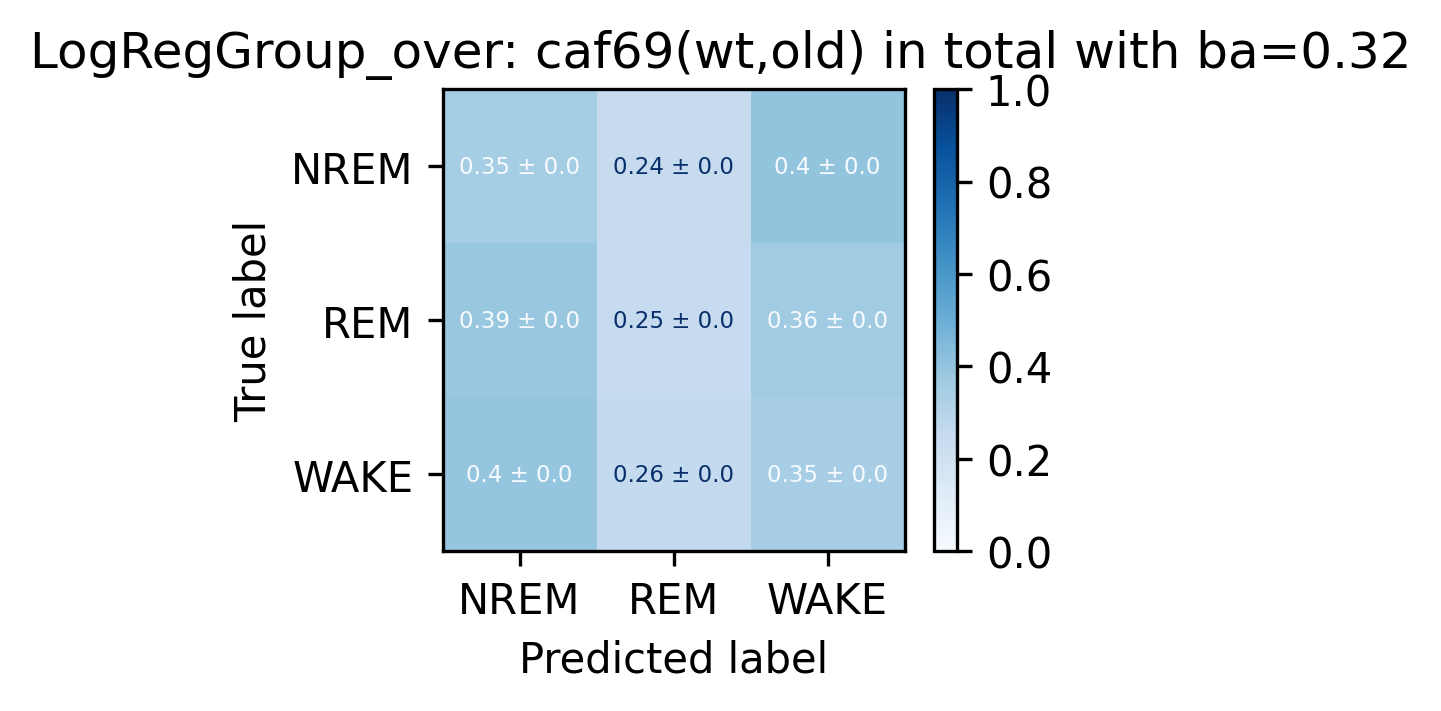

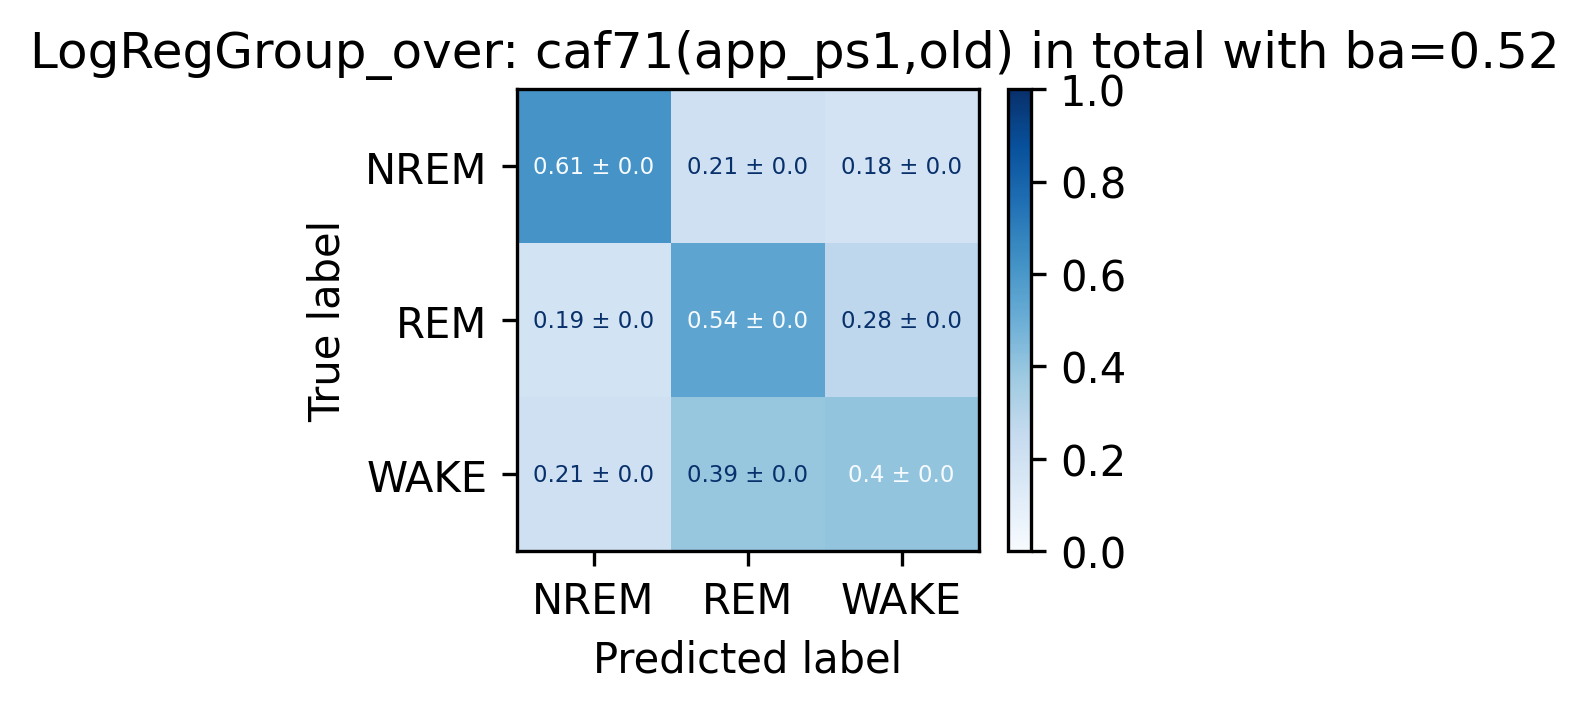

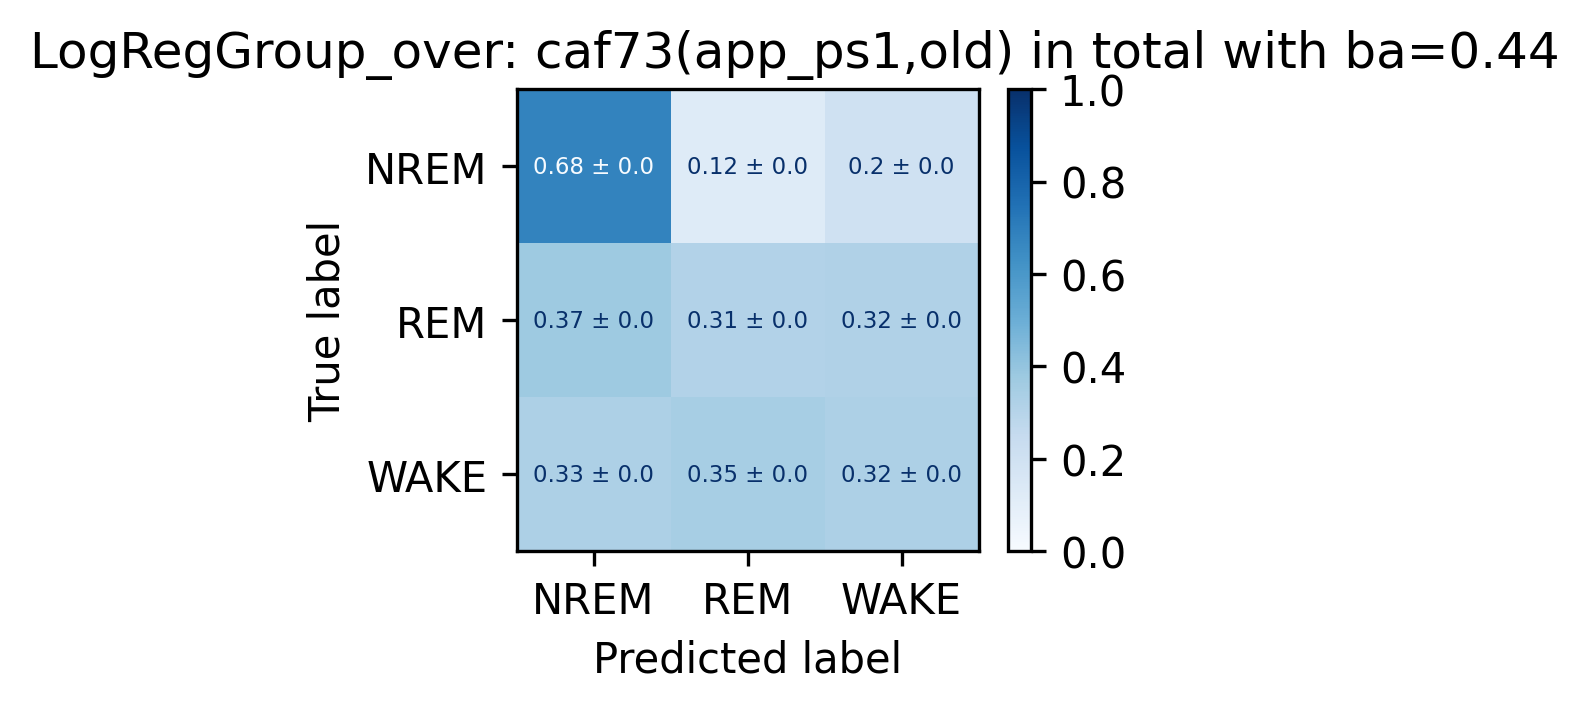

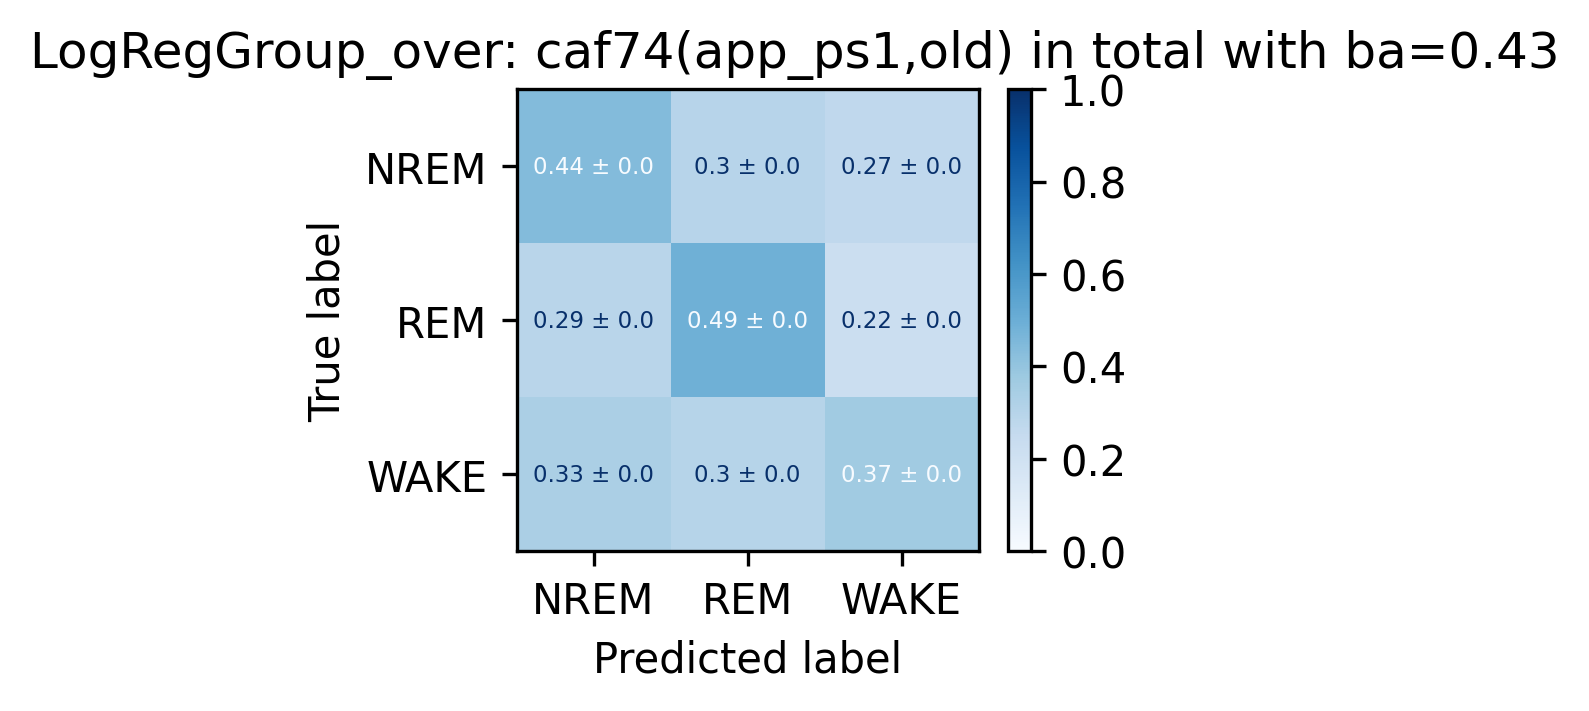

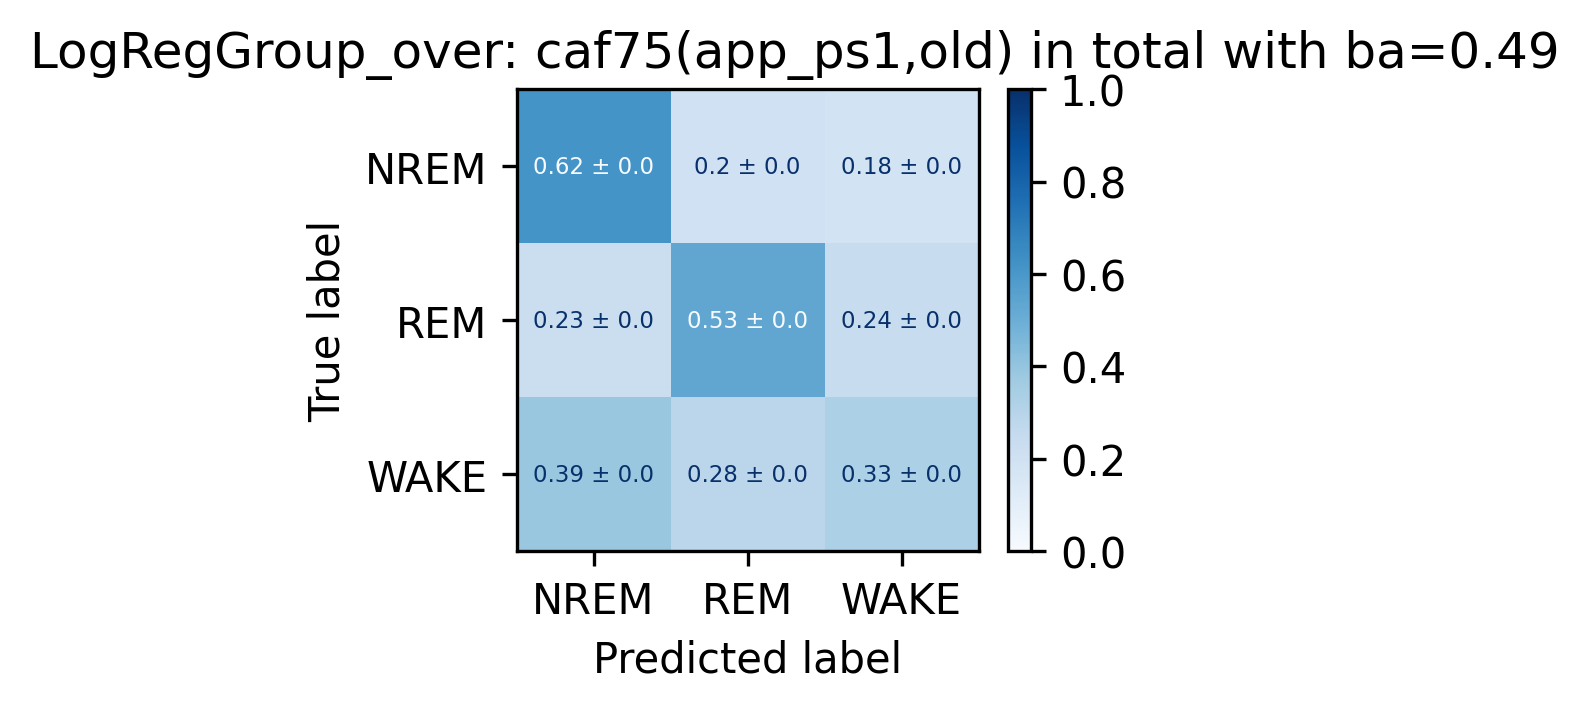

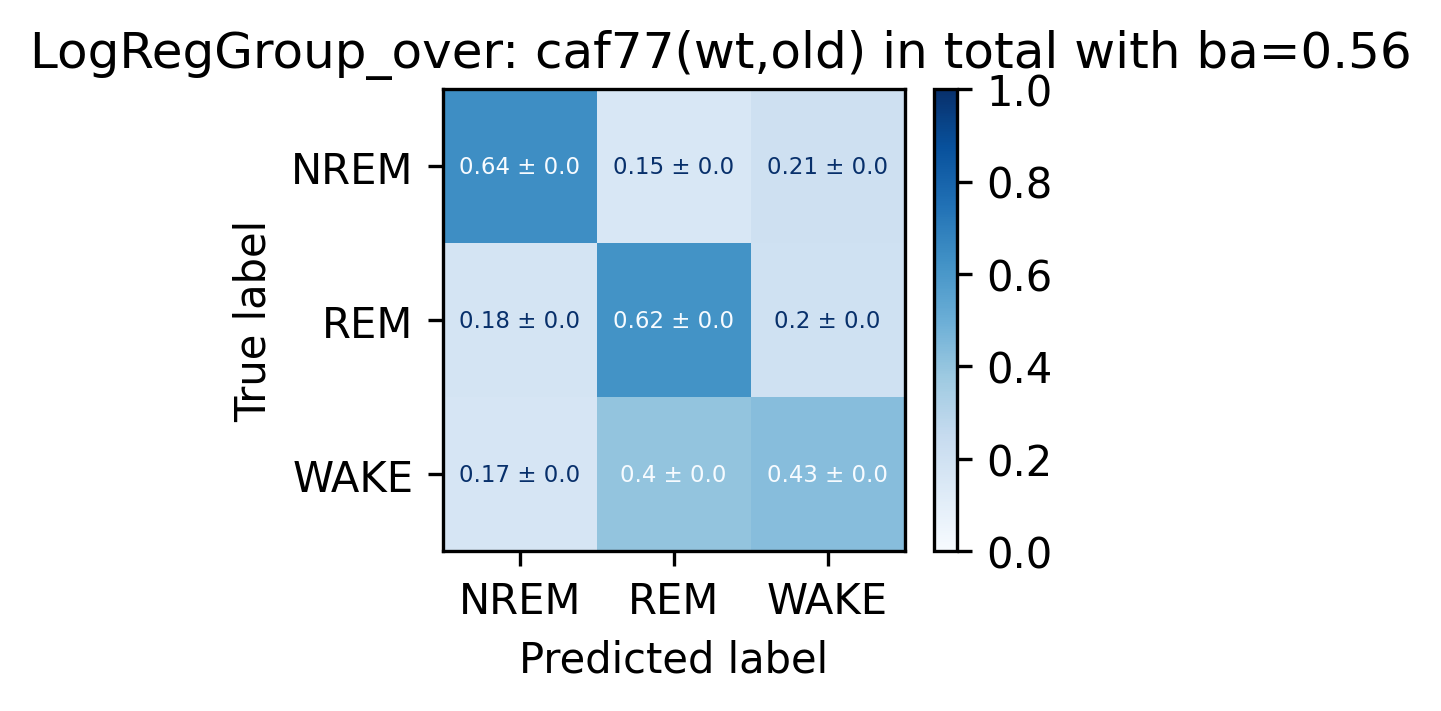

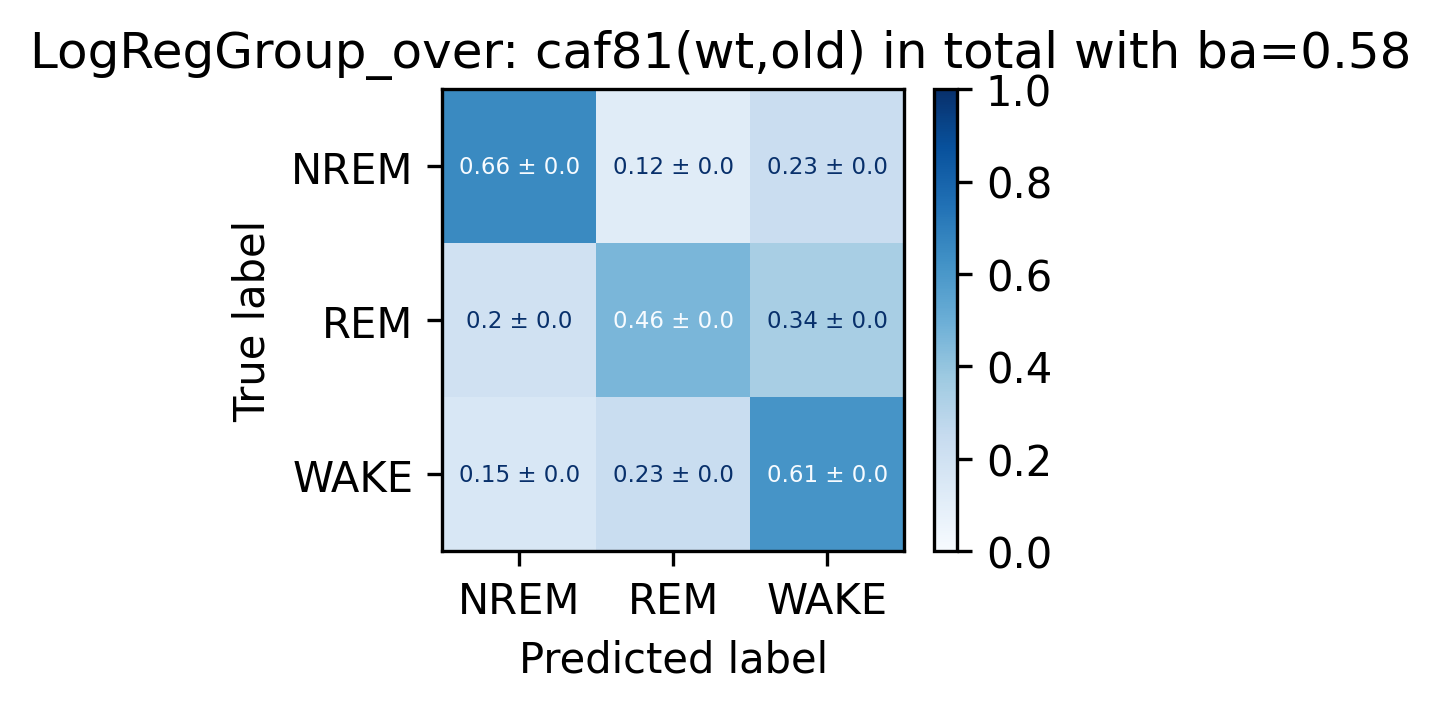

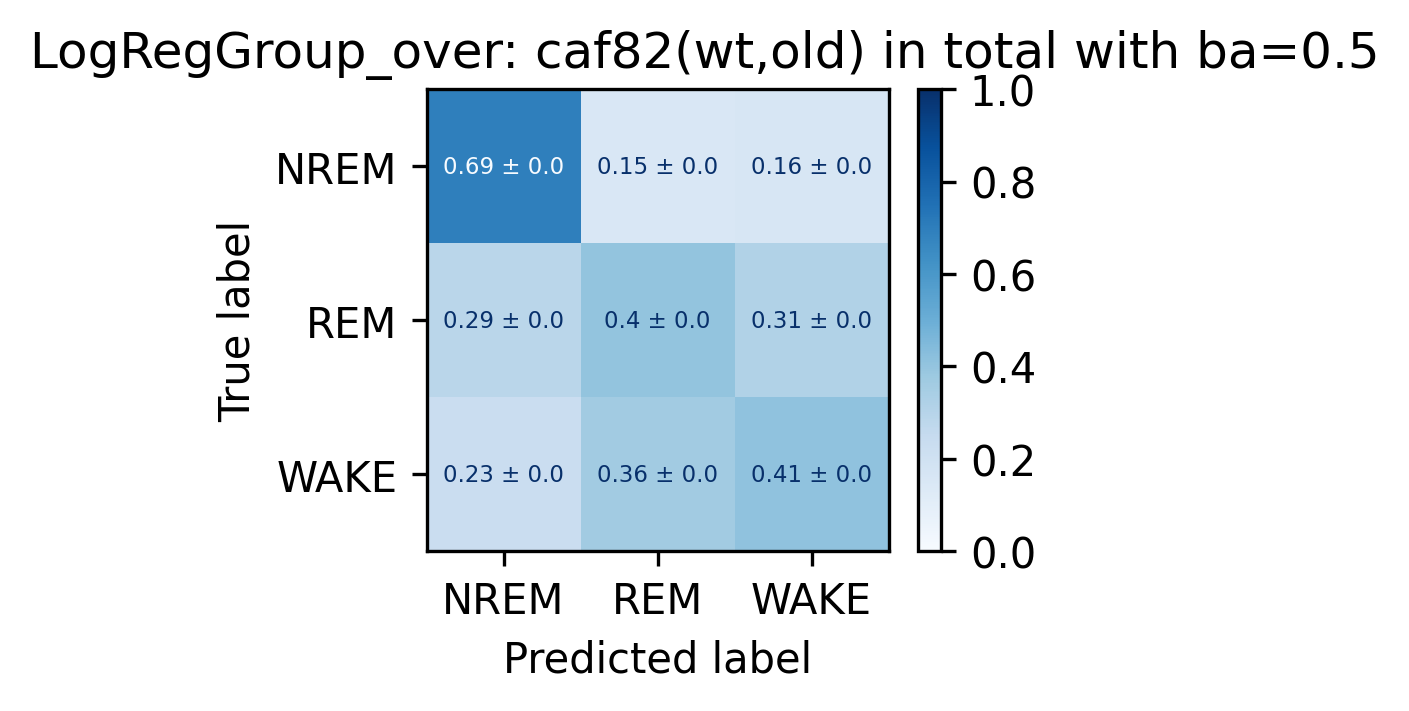

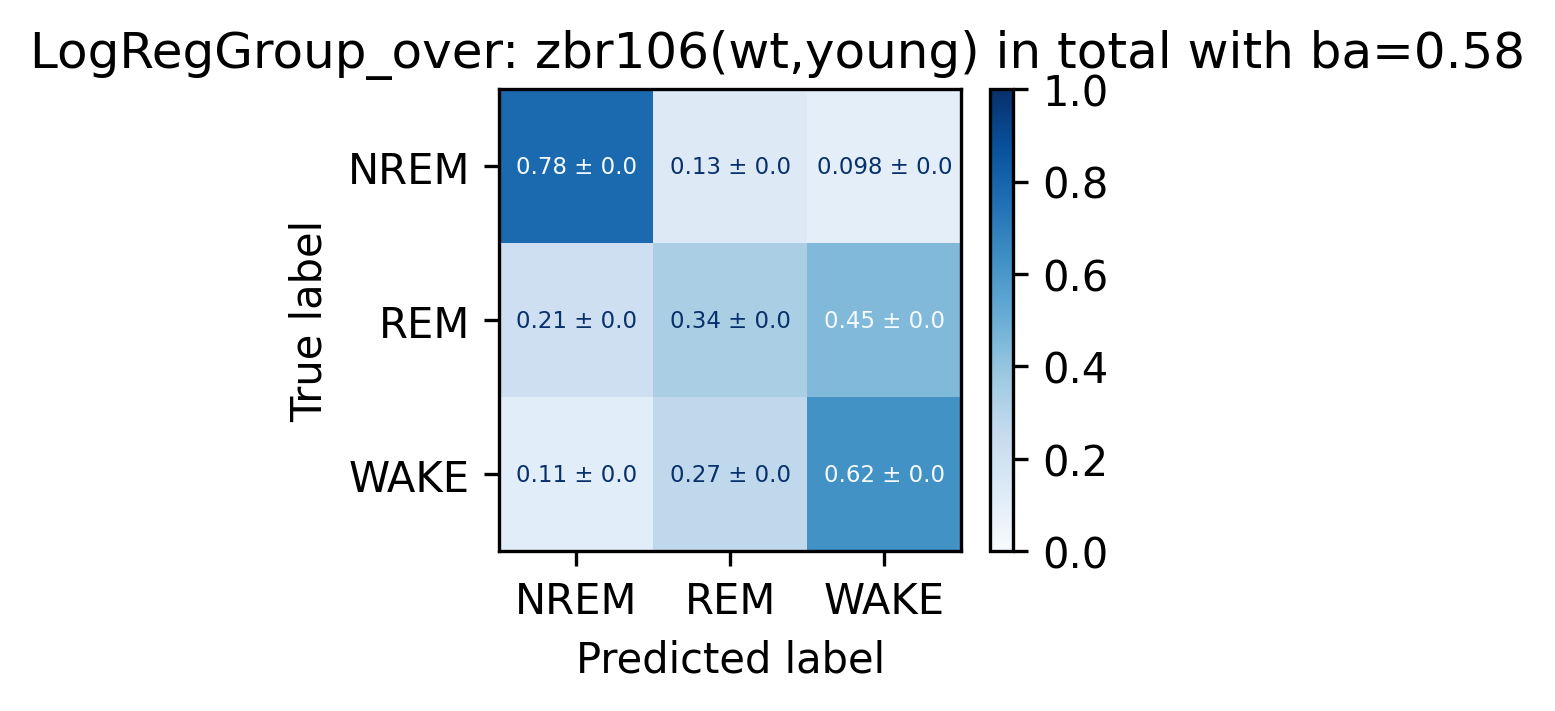

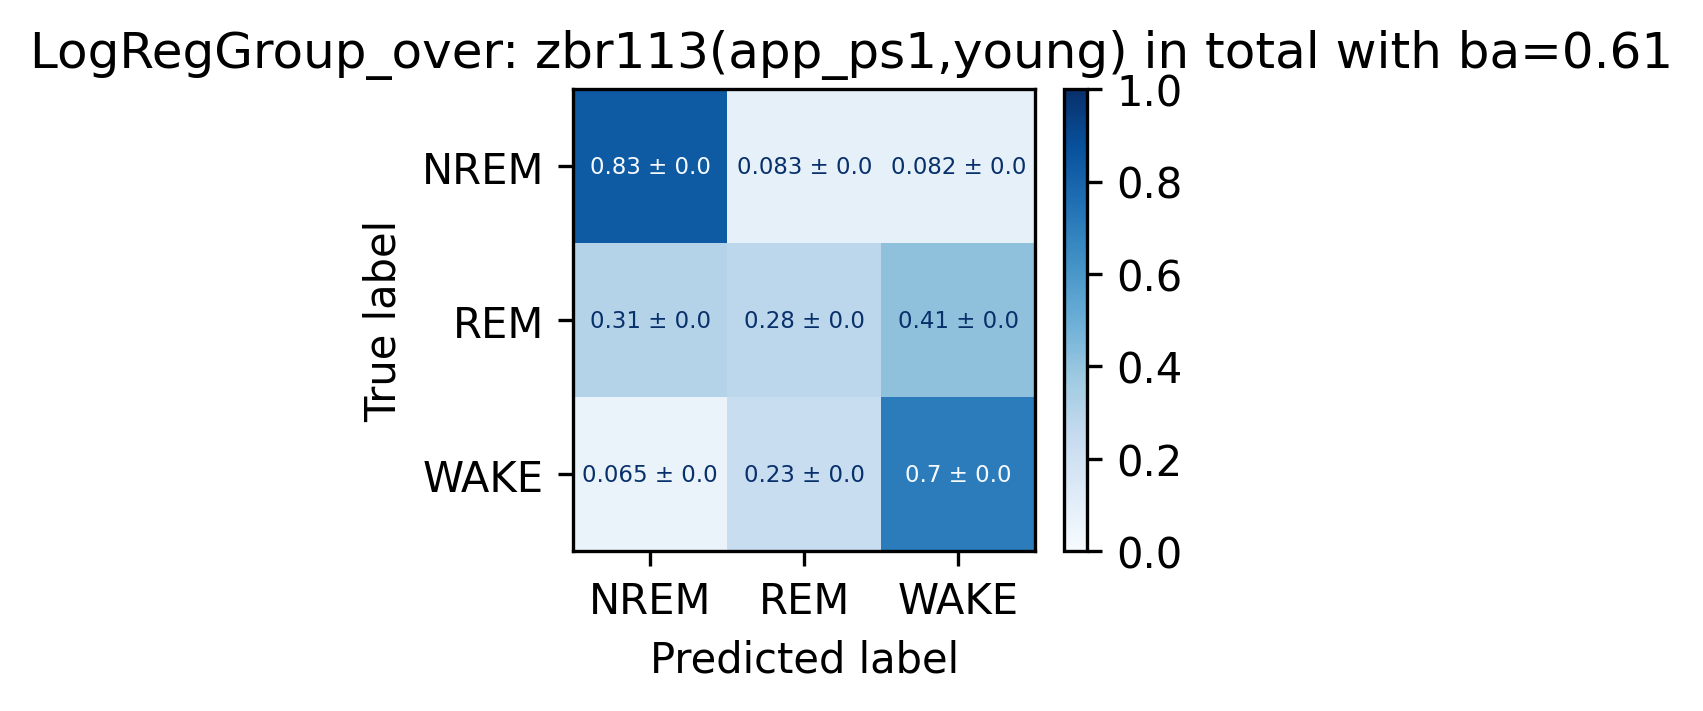

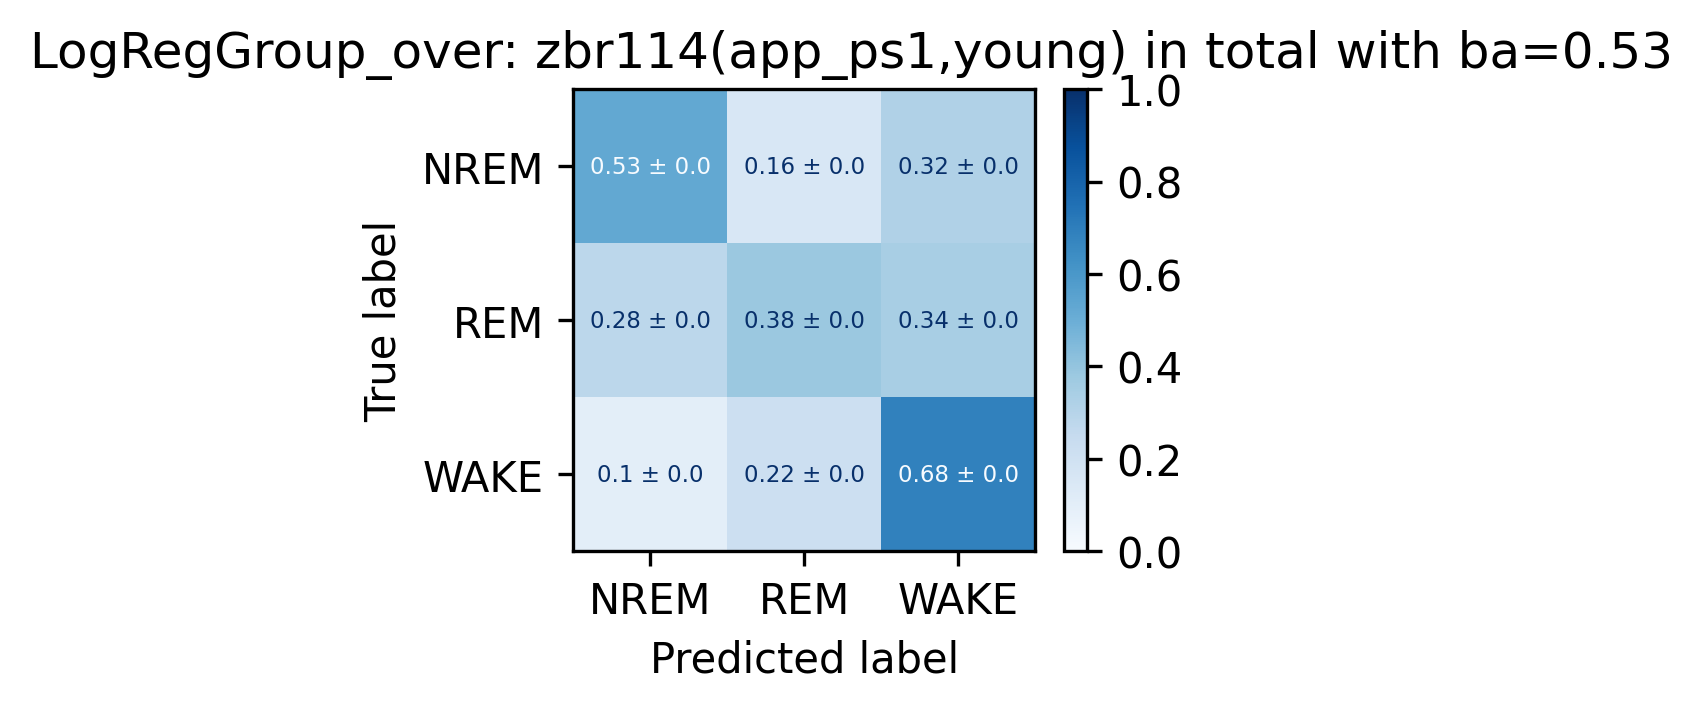

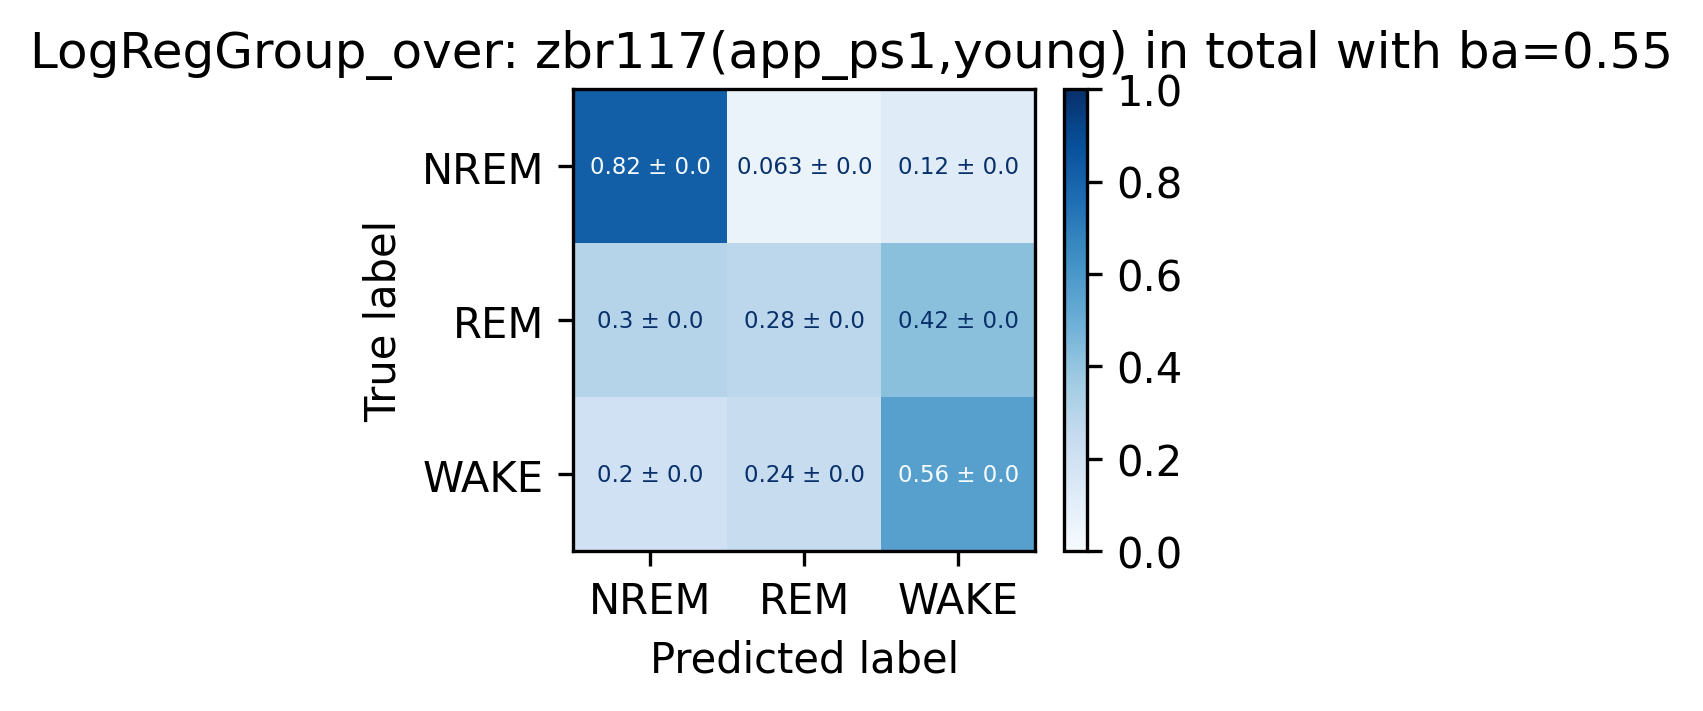

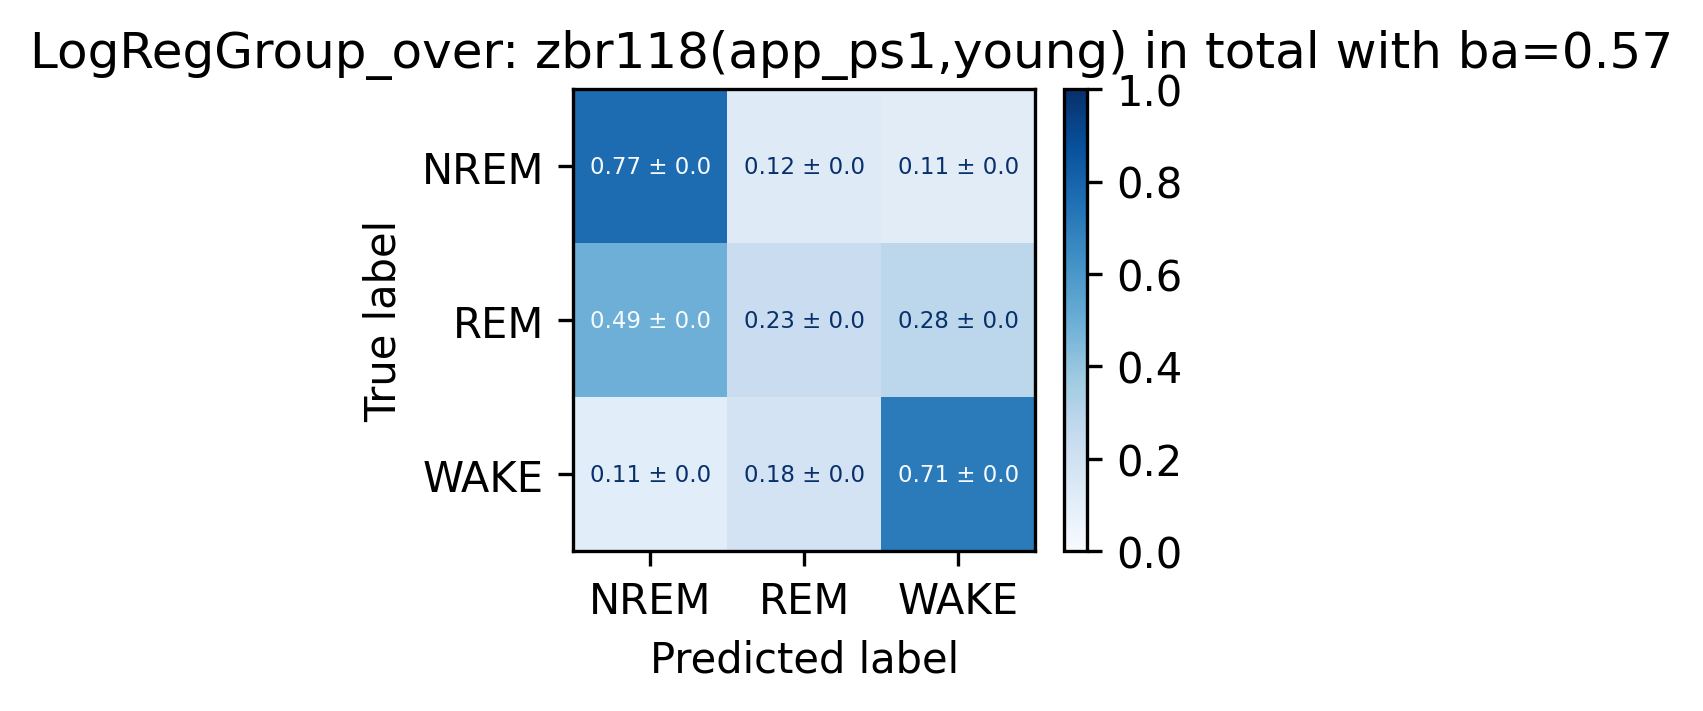

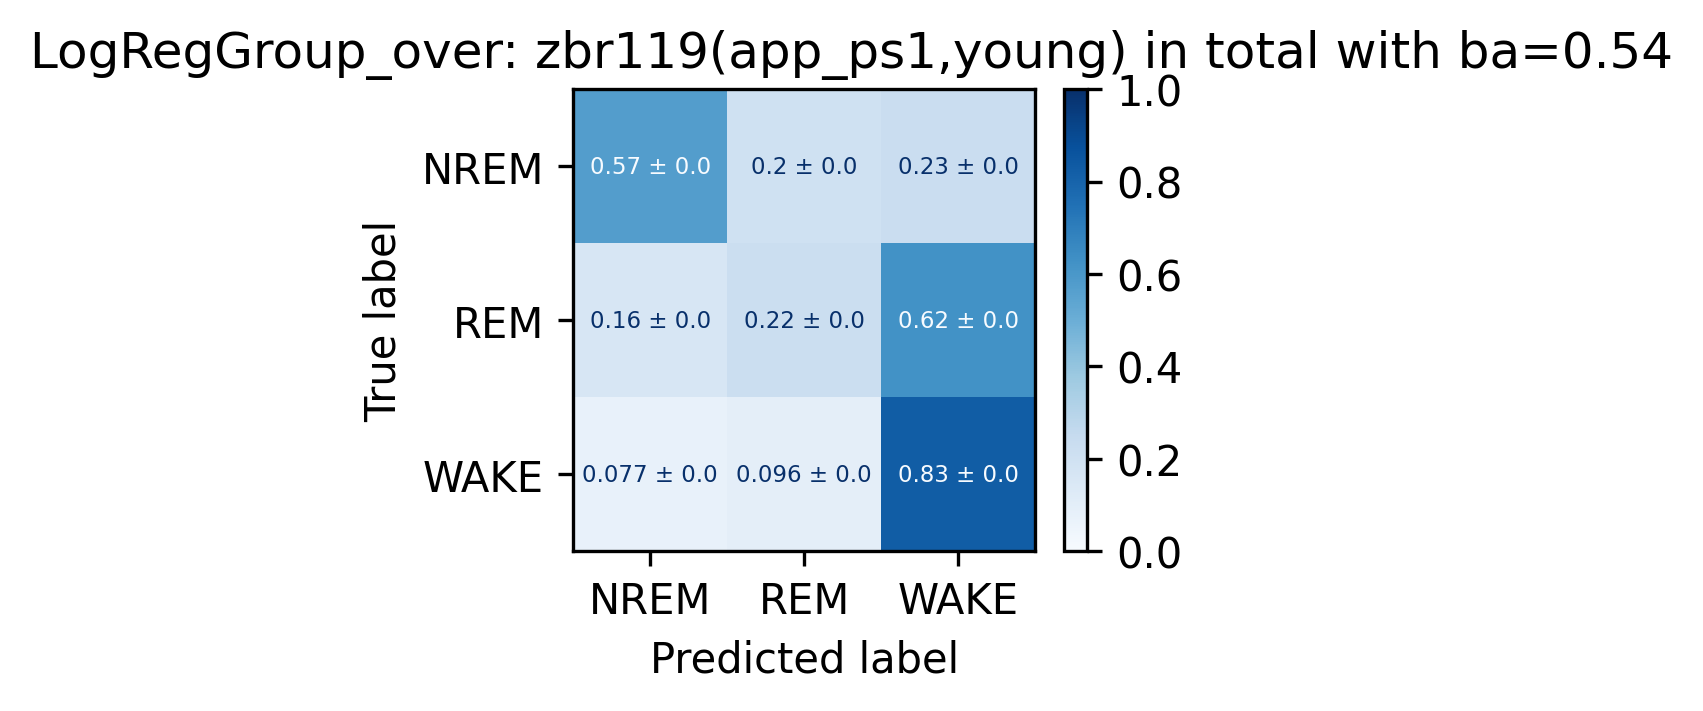

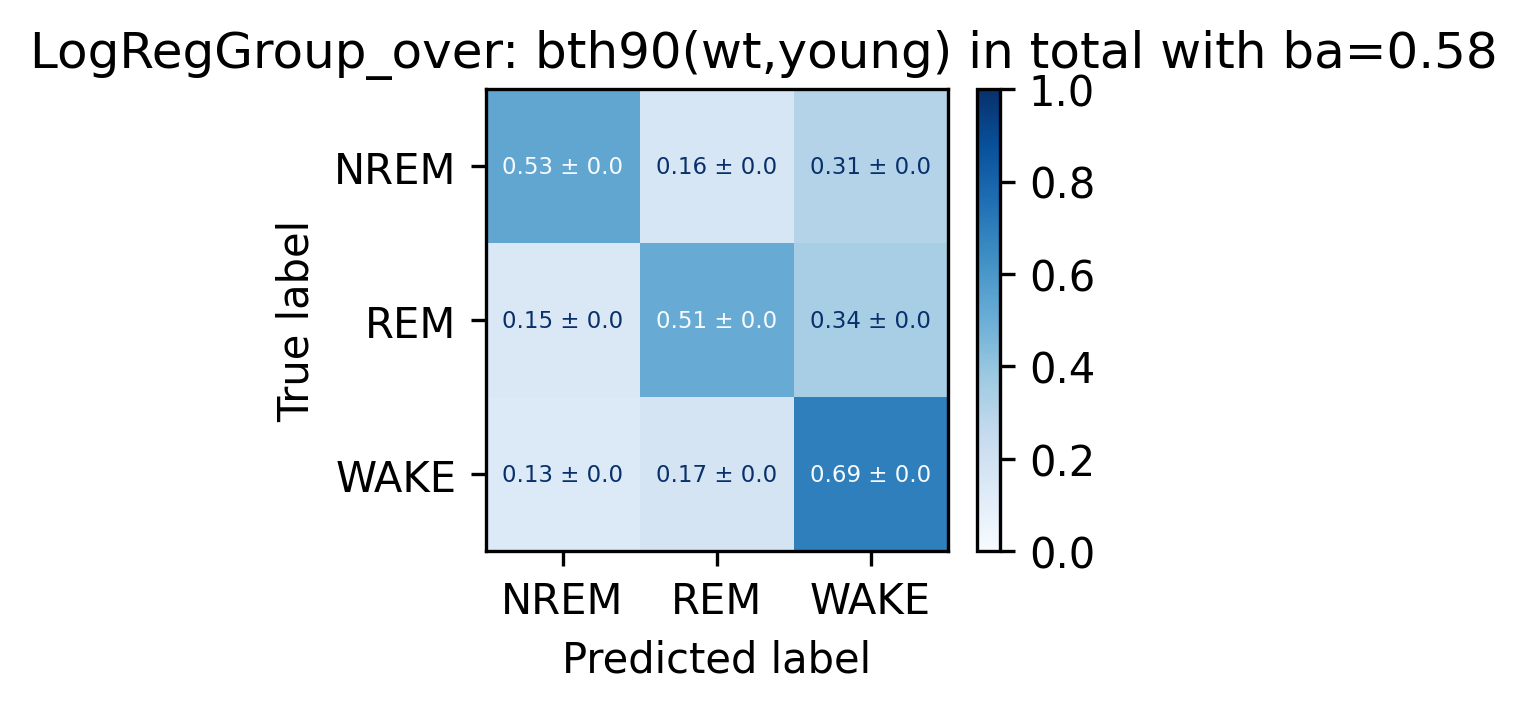

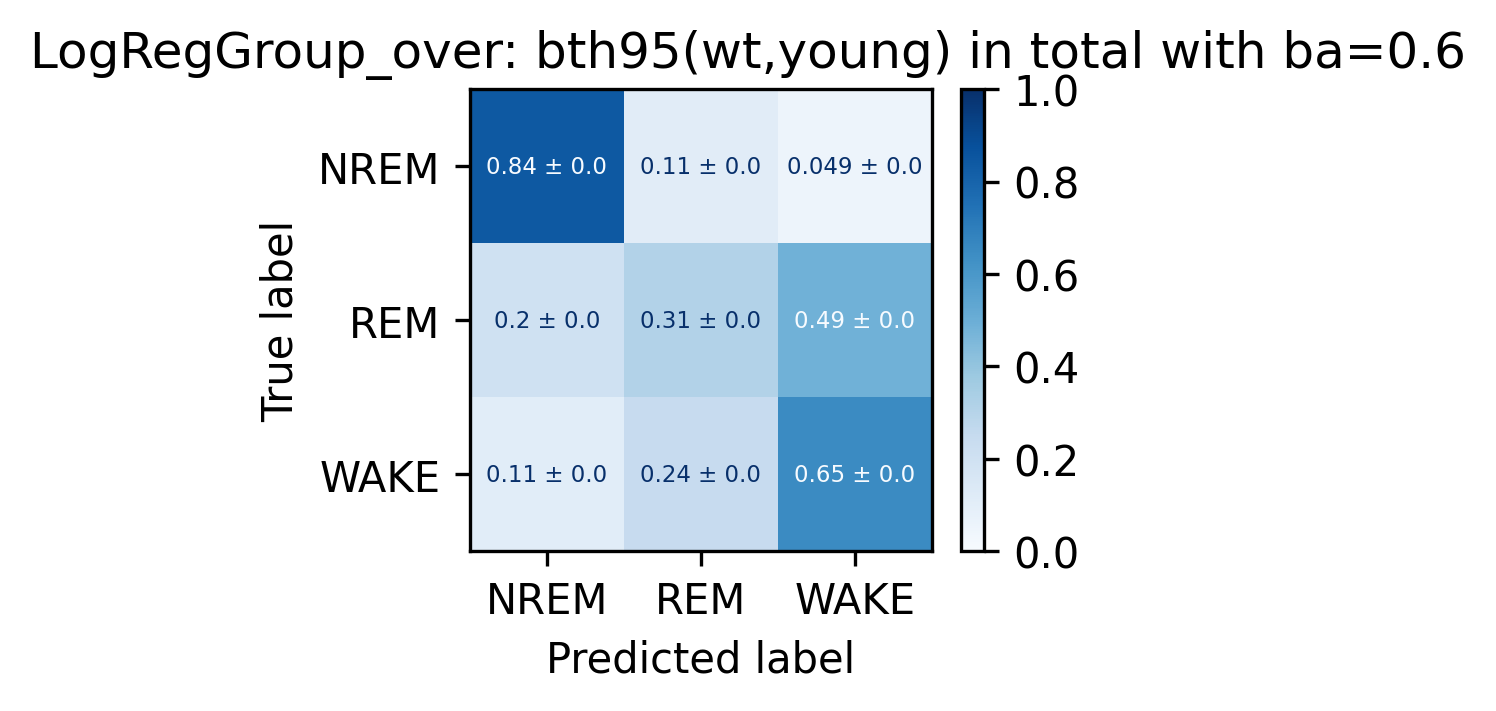

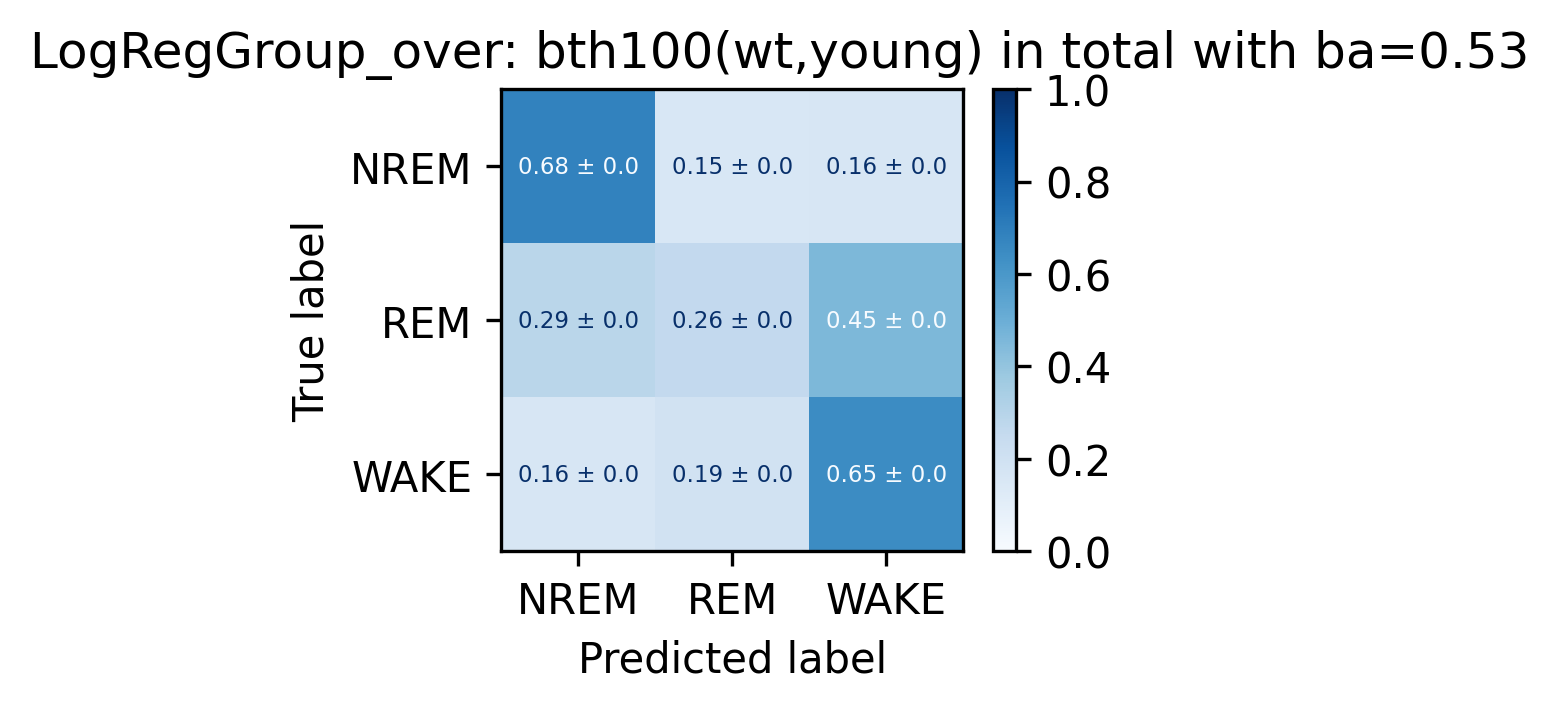

In [43]:
for key, val in cms.items():
    get_mean_cms_visual(val, graphic_train, key, subplot_kwargs={'figsize':(2.5,2), 'dpi':300}, 
                        alt_se=True, addon_text=False, addon_suff='poster_sw', parent_file_p='', savefig=False,
                       text_kw={'fontsize':5.5}, norm_size=3, **grouping_vars)

Datapoints per: 4315, 4315, 4315, 4315
0.0 111.57196572124323
0.0 106.11876690659527
1.5856423718594775e-284 38.91706007430124
0.0 87.94103571493076


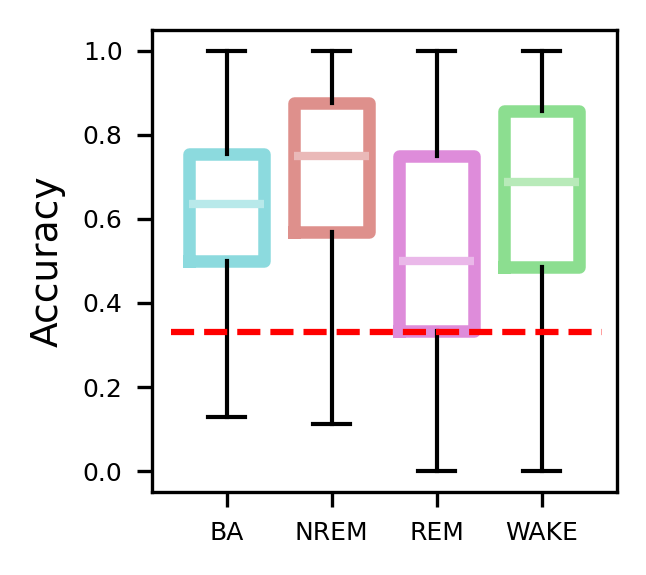

In [33]:
fig, ax = plt.subplots(1,1, figsize=(2,2), dpi=300)
stats, (_, pos) = diff_breakdown_box(cms['LogReg_over'], graphic_train, inner_d2=False, gap_between_groups=0.7, box_widths=0.5,ax=ax,
                  showfliers=False)
for group in stats:
    s = stats[group]
    for res in s:
        print(res.pvalue, res.statistic)
plt.ylabel("Accuracy", fontsize=9)
plt.xlabel("")
ax.tick_params(axis='both', which='major', labelsize=6)
#ax.tick_params(axis='both', which='minor', labelsize=8)
plt.hlines(0.33, 0.63, 3.5, color='r', linestyle='--')
# begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
# filename = f'{begin}poster/all/box_sleep_cond_3.svg'
# print(filename)
# fig.savefig(filename,bbox_inches="tight")